In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from tqdm import tqdm

In [2]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X_all = mnist['data'].astype(np.float32)
y_all = mnist['target'].astype(np.int64)

X_train_full = X_all[:60000].reshape(-1, 28, 28)
y_train_full = y_all[:60000]
X_test = X_all[60000:].reshape(-1, 28, 28)
y_test = y_all[60000:]

In [3]:
X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

X_train_full = X_train_full.reshape(-1, 28 * 28)
X_test = X_test.reshape(-1, 28 * 28)

X_val, y_val = X_train_full[55000:], y_train_full[55000:]
X_train, y_train = X_train_full[:55000], y_train_full[:55000]

def one_hot(y, num_classes=10):
    return np.eye(num_classes, dtype=np.float32)[y]

y_train_oh = one_hot(y_train)
y_val_oh = one_hot(y_val)
y_test_oh = one_hot(y_test)

print(f"  X_train: {X_train.shape}, y_train_oh: {y_train_oh.shape}")
print(f"  X_val:   {X_val.shape},   y_val_oh:   {y_val_oh.shape}")
print(f"  X_test:  {X_test.shape},  y_test_oh:  {y_test_oh.shape}")

  X_train: (55000, 784), y_train_oh: (55000, 10)
  X_val:   (5000, 784),   y_val_oh:   (5000, 10)
  X_test:  (10000, 784),  y_test_oh:  (10000, 10)


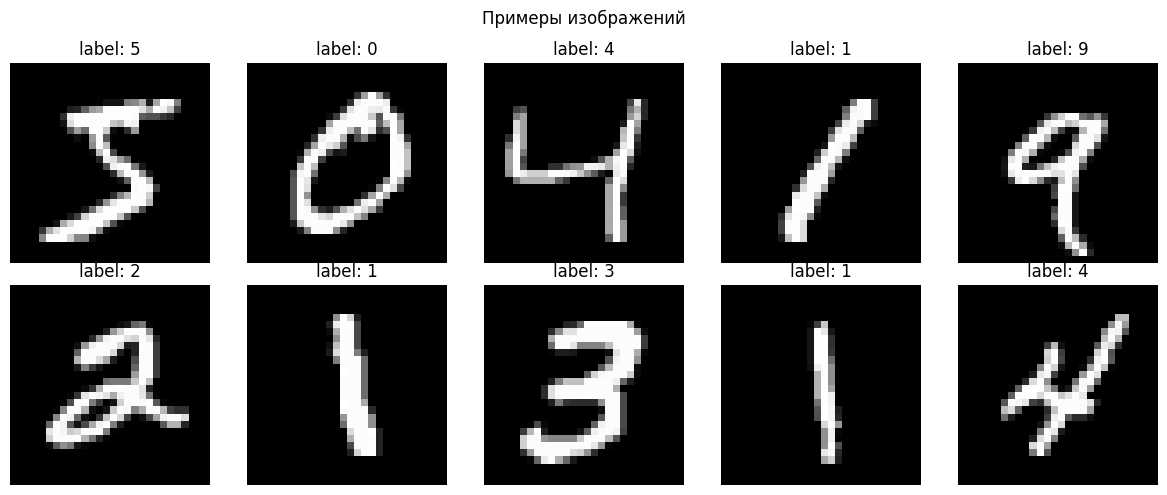

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"label: {y_train[i]}")
    ax.axis('off')
plt.suptitle("Примеры изображений")
plt.tight_layout()
plt.show()

In [5]:
def init_params(d0, d1, d2):
    W1 = np.random.randn(d1, d0).astype(np.float32) * np.sqrt(2.0 / d0)
    b1 = np.zeros(d1, dtype=np.float32)
    W2 = np.random.randn(d2, d1).astype(np.float32) * np.sqrt(2.0 / d1)
    b2 = np.zeros(d2, dtype=np.float32)
    return W1, b1, W2, b2

In [6]:
def relu(z):
    return np.maximum(0.0, z)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def cross_entropy(y_hat, y_true):
    eps = 1e-12
    return -np.mean(np.sum(y_true * np.log(y_hat + eps), axis=1))

In [7]:
def forward(X, W1, b1, W2, b2):
    z1 = X @ W1.T + b1
    a1 = relu(z1)
    z2 = a1 @ W2.T + b2
    y_hat = softmax(z2)
    cache = (X, z1, a1, z2, y_hat)
    return y_hat, cache

def backward(cache, y_true, W2):
    X, z1, a1, z2, y_hat = cache
    B = X.shape[0]

    dz2 = (y_hat - y_true) / B
    dW2 = dz2.T @ a1
    db2 = dz2.sum(axis=0)

    da1 = dz2 @ W2
    dz1 = da1 * (z1 > 0)
    dW1 = dz1.T @ X
    db1 = dz1.sum(axis=0)

    return dW1, db1, dW2, db2

In [8]:
def accuracy(X, y_true_labels, W1, b1, W2, b2, batch_size=512):
    correct = 0
    total = 0
    for i in range(0, len(X), batch_size):
        xb = X[i:i+batch_size]
        yb = y_true_labels[i:i+batch_size]
        z1 = xb @ W1.T + b1
        a1 = relu(z1)
        z2 = a1 @ W2.T + b2
        pred = z2.argmax(axis=1)
        correct += (pred == yb).sum()
        total += len(yb)
    return correct / total

In [9]:
s = 300
lr = 0.1
batch_size = 64
epochs = 20
num_classes = 10

W1, b1, W2, b2 = init_params(784, s, num_classes)

history = {
    "epoch": [],
    "loss": [],
    "train_acc": [],
    "val_acc": [],
    "time": []
}

N = len(X_train)

for epoch in range(epochs):
    t0 = time.time()

    idx = np.random.permutation(N)
    X_shuf = X_train[idx]
    y_shuf = y_train_oh[idx]

    epoch_loss = 0.0
    num_batches = 0

    pbar = tqdm(range(0, N, batch_size),
                desc=f"Epoch {epoch+1}/{epochs}",
                leave=False)
    for i in pbar:
        xb = X_shuf[i:i+batch_size]
        yb = y_shuf[i:i+batch_size]

        y_hat, cache = forward(xb, W1, b1, W2, b2)

        loss = cross_entropy(y_hat, yb)
        epoch_loss += loss
        num_batches += 1

        dW1, db1, dW2, db2 = backward(cache, yb, W2)

        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

        pbar.set_postfix({"loss": f"{loss:.4f}"})

    train_acc = accuracy(X_train, y_train, W1, b1, W2, b2)
    val_acc = accuracy(X_val, y_val, W1, b1, W2, b2)
    avg_loss = epoch_loss / num_batches
    elapsed = time.time() - t0

    history["epoch"].append(epoch + 1)
    history["loss"].append(avg_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["time"].append(elapsed)

    print(f"Epoch {epoch+1:2d}/{epochs} | "
          f"loss={avg_loss:.4f} | "
          f"train_acc={train_acc*100:.2f}% | "
          f"val_acc={val_acc*100:.2f}% | "
          f"time={elapsed:.1f}s")

test_acc = accuracy(X_test, y_test, W1, b1, W2, b2)
print(f"\nТочность на тестовой выборке: {test_acc*100:.2f}%")

Epoch  1/20 | loss=0.3760 | train_acc=92.71% | val_acc=94.60% | time=2.7s


Epoch  2/20 | loss=0.2004 | train_acc=95.29% | val_acc=96.44% | time=2.8s


Epoch  3/20 | loss=0.1494 | train_acc=96.40% | val_acc=96.94% | time=2.8s


Epoch  4/20 | loss=0.1195 | train_acc=97.04% | val_acc=97.32% | time=2.8s


Epoch  5/20 | loss=0.0993 | train_acc=97.59% | val_acc=97.74% | time=3.1s


...

Epoch 16/20 | loss=0.0276 | train_acc=99.60% | val_acc=98.18% | time=2.6s


Epoch 17/20 | loss=0.0253 | train_acc=99.61% | val_acc=98.36% | time=2.6s


Epoch 18/20 | loss=0.0231 | train_acc=99.67% | val_acc=98.20% | time=2.6s


Epoch 19/20 | loss=0.0212 | train_acc=99.68% | val_acc=98.18% | time=2.6s


Epoch 20/20 | loss=0.0193 | train_acc=99.58% | val_acc=97.92% | time=2.7s

Точность на тестовой выборке: 97.91%


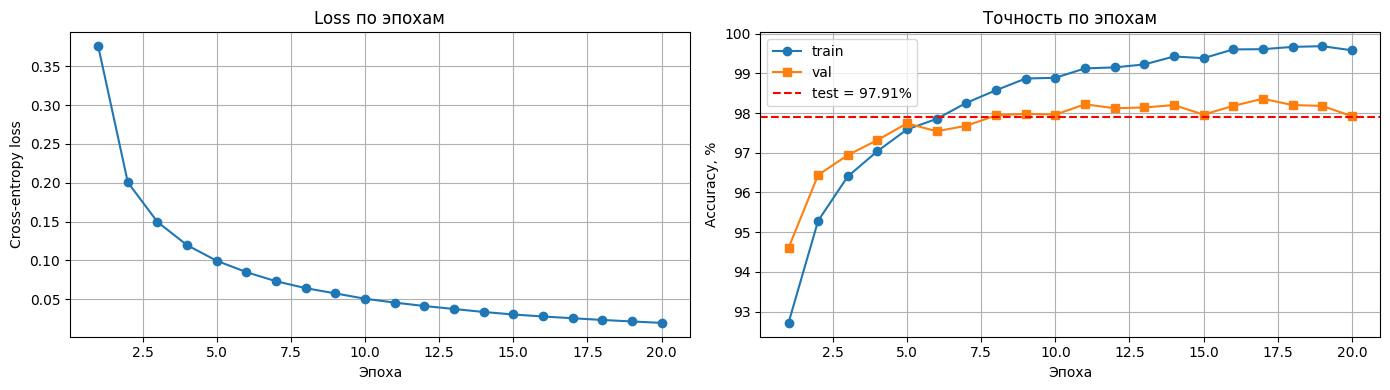

Суммарное время обучения: 55.6 сек
Среднее время эпохи: 2.8 сек


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history["epoch"], history["loss"], marker='o')
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Loss по эпохам")
axes[0].grid(True)

axes[1].plot(history["epoch"], [a*100 for a in history["train_acc"]],
             marker='o', label="train")
axes[1].plot(history["epoch"], [a*100 for a in history["val_acc"]],
             marker='s', label="val")
axes[1].axhline(test_acc*100, color='r', linestyle='--',
                label=f"test = {test_acc*100:.2f}%")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy, %")
axes[1].set_title("Точность по эпохам")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

total_time = sum(history["time"])
print(f"Суммарное время обучения: {total_time:.1f} сек")
print(f"Среднее время эпохи: {np.mean(history['time']):.1f} сек")

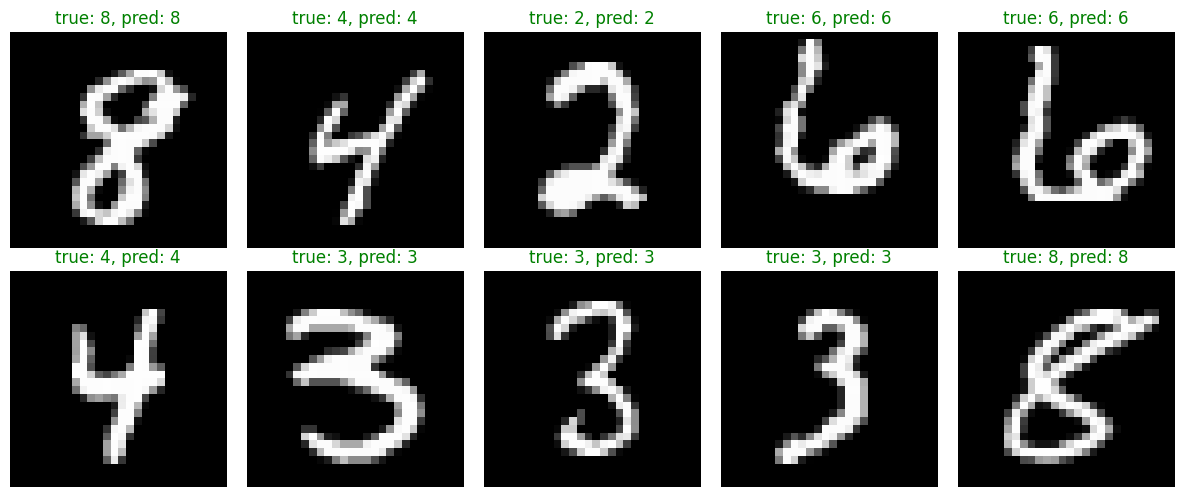

In [11]:
idxs = np.random.choice(len(X_test), 10, replace=False)
X_show = X_test[idxs]
y_show = y_test[idxs]

z1 = X_show @ W1.T + b1
a1 = relu(z1)
z2 = a1 @ W2.T + b2
preds = z2.argmax(axis=1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, img, true, pred in zip(axes.flat, X_show, y_show, preds):
    ax.imshow(img.reshape(28, 28), cmap='gray')
    color = 'green' if true == pred else 'red'
    ax.set_title(f"true: {true}, pred: {pred}", color=color)
    ax.axis('off')
plt.tight_layout()
plt.show()